<a href="https://colab.research.google.com/github/Desconocidoname/rutas-evacuacion-inundacion/blob/main/rutas_inundacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Rutas de evacuación en una zona inundada

**Equipo:**

Ángel De Anda Gómez – Modelo del problema (secciones 1, 2 y 4): representación del terreno, función de costo con riesgo (α) y validador de rutas.

David Mendoza Avalos – Algoritmos de búsqueda (secciones 3 y 5): BFS, DFS, Dijkstra, A* y Greedy, medición de métricas y visualización de rutas.

Rebeca Fields Gómez– Pruebas (secciones 6, 7 y 9): los 5 escenarios obligatorios, la prueba adicional para detectar errores y el resumen de pruebas.

Ladino Hernandez Juan Daniel– Comparación, conclusiones y repositorio (secciones 8 y 10): comparación en mapas grandes y conclusiones. Además, juntó las partes en el notebook final, creó el repositorio en GitHub, subió los archivos.

**Problema.** Después de una inundación, un agente debe desplazarse desde una zona afectada hasta un refugio. El terreno es una cuadrícula donde cada celda tiene un nivel de inundación: algunas se pueden cruzar con poco riesgo, otras con más riesgo y otras están bloqueadas.

**Objetivo.** No solo encontrar *una* ruta, sino encontrar la ruta *más conveniente*, comparar varias estrategias de búsqueda (BFS, DFS, Dijkstra, A* y Greedy) y comprobar con pruebas que las rutas respetan las condiciones del escenario.


**Contenido**
1. Representación del terreno
2. Cómo se incorpora el riesgo
3. Estrategias de búsqueda
4. Validación de rutas
5. Ejecución, métricas y visualización
6. Escenarios de prueba (5 obligatorios)
7. Prueba adicional para detectar errores
8. Comparación en mapas más grandes
9. Resumen de pruebas
10. Decisiones de diseño y conclusiones
11. Declaración de uso de IA

In [ ]:
import heapq
import itertools
import random
import time
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

pd.set_option("display.width", 140)

## 1. Representación del terreno

El terreno es una matriz de NumPy. Cada celda guarda su **nivel de inundación**:

| Valor | Significado | ¿Se puede cruzar? | Riesgo |
|---|---|---|---|
| 0 | Seco | Sí | 0 |
| 1 | Inundación baja | Sí | 1 |
| 2 | Inundación media | Sí | 2 |
| 3 | Inundación alta | **No (bloqueado)** | — |

El agente se mueve en 4 direcciones (arriba, abajo, izquierda, derecha). No se permiten diagonales para que un movimiento nunca "corte esquinas" entre dos celdas bloqueadas.

El mapa base de 12x12 está diseñado a propósito: el camino recto del inicio al refugio cruza una zona central con inundación media, mientras que existe un rodeo más largo por terreno seco. Así se puede observar cuándo conviene el camino corto y cuándo el seguro.

In [ ]:
# Niveles de inundación
SECO, BAJO, MEDIO, BLOQUEADO = 0, 1, 2, 3
NOMBRE_NIVEL = {
    SECO: "Seco (riesgo 0)",
    BAJO: "Inundación baja (riesgo 1)",
    MEDIO: "Inundación media (riesgo 2)",
    BLOQUEADO: "Inundación alta (bloqueado)",
}

# Movimientos permitidos: arriba, derecha, abajo, izquierda
MOVIMIENTOS = [(-1, 0), (0, 1), (1, 0), (0, -1)]


def crear_mapa_base():
    """Mapa 12x12. Devuelve una copia nueva en cada llamada para que
    modificar un escenario no altere a los demás."""
    return np.array([
        [0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0],
        [0, 3, 0, 0, 0, 3, 3, 0, 0, 0, 3, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 3, 0, 2, 2, 2, 2, 0, 3, 0, 1],
        [0, 0, 3, 0, 2, 2, 2, 2, 0, 3, 0, 0],
        [0, 0, 0, 0, 2, 2, 2, 2, 0, 0, 0, 0],
        [0, 1, 3, 0, 2, 2, 2, 2, 0, 3, 1, 0],
        [0, 1, 3, 0, 2, 2, 2, 2, 0, 3, 0, 0],
        [0, 0, 0, 0, 2, 2, 2, 2, 0, 0, 0, 0],
        [1, 1, 0, 3, 0, 0, 0, 0, 3, 0, 1, 1],
        [0, 0, 0, 3, 1, 1, 1, 1, 3, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    ])


INICIO = (5, 0)    # (fila, columna): zona afectada
REFUGIO = (5, 11)  # refugio


def generar_mapa(n, semilla, p_bloqueo=0.2, p_bajo=0.2, p_medio=0.15):
    """Mapa aleatorio n x n reproducible (misma semilla = mismo mapa).
    El inicio (0,0) y el refugio (n-1,n-1) siempre quedan secos."""
    rng = np.random.default_rng(semilla)
    p_seco = 1 - p_bloqueo - p_bajo - p_medio
    mapa = rng.choice([SECO, BAJO, MEDIO, BLOQUEADO], size=(n, n),
                      p=[p_seco, p_bajo, p_medio, p_bloqueo])
    mapa[0, 0] = SECO
    mapa[n - 1, n - 1] = SECO
    return mapa


def dentro(grid, pos):
    f, c = pos
    return 0 <= f < grid.shape[0] and 0 <= c < grid.shape[1]


def es_transitable(grid, pos):
    return dentro(grid, pos) and grid[pos] != BLOQUEADO


def vecinos(grid, pos):
    """Celdas vecinas a las que el agente puede moverse."""
    f, c = pos
    for df, dc in MOVIMIENTOS:
        siguiente = (f + df, c + dc)
        if es_transitable(grid, siguiente):
            yield siguiente

## 2. Cómo se incorpora el riesgo

Cada vez que el agente **entra** a una celda paga un costo:

$$\text{costo}(celda) = 1 + \alpha \cdot \text{riesgo}(celda)$$

- El **1** representa la distancia (un paso).
- **riesgo** es el nivel de inundación (0, 1 o 2).
- **α ≥ 0** indica cuánto pesa el riesgo frente a la distancia:
  - α = 0 → solo importa la distancia (el camino más corto).
  - α grande → se prefiere caminar más con tal de evitar el agua.

El costo de una ruta es la suma de los costos de todas las celdas a las que entra. **La mejor ruta es la de menor costo total.** Si una ruta es más corta pero cruza zonas de mayor riesgo, el sistema compara ambos costos totales y elige el menor; el valor de α decide el punto en que conviene más rodear.

Las celdas bloqueadas no tienen costo: simplemente nunca se generan como vecinas.

In [ ]:
def costo_paso(grid, destino, alpha):
    """Costo de entrar a la celda 'destino'."""
    return 1.0 + alpha * float(grid[destino])


def costo_ruta(grid, ruta, alpha):
    """Costo total de una ruta, recalculado desde el mapa."""
    return sum(costo_paso(grid, p, alpha) for p in ruta[1:])


def riesgo_ruta(grid, ruta):
    """Suma de los niveles de riesgo de las celdas por las que pasa la ruta."""
    return int(sum(grid[p] for p in ruta[1:]))


def reconstruir(padres, objetivo):
    """Recorre los padres desde el objetivo hasta el inicio."""
    ruta = []
    actual = objetivo
    while actual is not None:
        ruta.append(actual)
        actual = padres[actual]
    return ruta[::-1]


def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

## 3. Estrategias de búsqueda

Todas las funciones reciben `(grid, inicio, refugio, alpha)` y devuelven `(ruta, nodos_expandidos, costo_interno)`. Si no existe ruta devuelven `ruta = None`.

| Algoritmo | ¿Usa el riesgo? | ¿Garantiza la ruta de menor costo? | Idea |
|---|---|---|---|
| **BFS** | No | No (solo la de menos pasos) | Explora por niveles. Sirve para *encontrar una ruta*. |
| **DFS** | No | No | Explora un camino hasta el fondo antes de regresar. |
| **Dijkstra (UCS)** | Sí | **Sí** | Expande siempre el nodo con menor costo acumulado *g*. |
| **A\*** | Sí | **Sí** (con heurística admisible) | Igual que Dijkstra, pero ordena por *g + h*. |
| **Greedy** | No (solo la heurística) | No | Va hacia donde *parece* más cerca el refugio. |

**Heurística de A\*:** distancia Manhattan al refugio. Es **admisible** porque cada paso cuesta como mínimo 1 (cuando α ≥ 0), así que nunca sobreestima el costo real. También es **consistente**, por lo que se puede usar un conjunto de cerrados sin perder optimalidad.

**Trabajo realizado:** se cuenta un *nodo expandido* cada vez que un algoritmo saca una celda de su frontera y revisa sus vecinos.

In [ ]:
def _extremos_validos(grid, inicio, refugio):
    return es_transitable(grid, inicio) and es_transitable(grid, refugio)


def bfs(grid, inicio, refugio, alpha=1.0):
    if not _extremos_validos(grid, inicio, refugio):
        return None, 0, None
    frontera = deque([inicio])
    padres = {inicio: None}
    expandidos = 0
    while frontera:
        actual = frontera.popleft()
        expandidos += 1
        if actual == refugio:
            return reconstruir(padres, actual), expandidos, None
        for v in vecinos(grid, actual):
            if v not in padres:
                padres[v] = actual
                frontera.append(v)
    return None, expandidos, None


def dfs(grid, inicio, refugio, alpha=1.0):
    if not _extremos_validos(grid, inicio, refugio):
        return None, 0, None
    pila = [inicio]
    padres = {inicio: None}
    visitados = set()
    expandidos = 0
    while pila:
        actual = pila.pop()
        if actual in visitados:
            continue
        visitados.add(actual)
        expandidos += 1
        if actual == refugio:
            return reconstruir(padres, actual), expandidos, None
        for v in vecinos(grid, actual):
            if v not in visitados:
                padres[v] = actual
                pila.append(v)
    return None, expandidos, None


def dijkstra(grid, inicio, refugio, alpha=1.0):
    if not _extremos_validos(grid, inicio, refugio):
        return None, 0, None
    desempate = itertools.count()   # evita comparar tuplas de posiciones en empates
    frontera = [(0.0, next(desempate), inicio)]
    g = {inicio: 0.0}
    padres = {inicio: None}
    cerrados = set()
    expandidos = 0
    while frontera:
        g_actual, _, actual = heapq.heappop(frontera)
        if actual in cerrados:          # entrada vieja de la cola
            continue
        cerrados.add(actual)
        expandidos += 1
        if actual == refugio:
            return reconstruir(padres, actual), expandidos, g_actual
        for v in vecinos(grid, actual):
            nuevo_g = g_actual + costo_paso(grid, v, alpha)
            if v not in cerrados and nuevo_g < g.get(v, float("inf")):
                g[v] = nuevo_g
                padres[v] = actual
                heapq.heappush(frontera, (nuevo_g, next(desempate), v))
    return None, expandidos, None


def a_estrella(grid, inicio, refugio, alpha=1.0, peso_heuristica=1.0):
    """peso_heuristica = 1 es A* normal. Un peso > 1 la vuelve NO admisible;
    solo se usa en la prueba adicional para demostrar que la prueba detecta errores."""
    if not _extremos_validos(grid, inicio, refugio):
        return None, 0, None
    h = lambda p: peso_heuristica * manhattan(p, refugio)
    desempate = itertools.count()
    frontera = [(h(inicio), next(desempate), 0.0, inicio)]
    g = {inicio: 0.0}
    padres = {inicio: None}
    cerrados = set()
    expandidos = 0
    while frontera:
        _, _, g_actual, actual = heapq.heappop(frontera)
        if actual in cerrados:
            continue
        cerrados.add(actual)
        expandidos += 1
        if actual == refugio:
            return reconstruir(padres, actual), expandidos, g_actual
        for v in vecinos(grid, actual):
            nuevo_g = g_actual + costo_paso(grid, v, alpha)
            if v not in cerrados and nuevo_g < g.get(v, float("inf")):
                g[v] = nuevo_g
                padres[v] = actual
                heapq.heappush(frontera, (nuevo_g + h(v), next(desempate), nuevo_g, v))
    return None, expandidos, None


def greedy(grid, inicio, refugio, alpha=1.0):
    if not _extremos_validos(grid, inicio, refugio):
        return None, 0, None
    desempate = itertools.count()
    frontera = [(manhattan(inicio, refugio), next(desempate), inicio)]
    padres = {inicio: None}
    cerrados = set()
    expandidos = 0
    while frontera:
        _, _, actual = heapq.heappop(frontera)
        if actual in cerrados:
            continue
        cerrados.add(actual)
        expandidos += 1
        if actual == refugio:
            return reconstruir(padres, actual), expandidos, None
        for v in vecinos(grid, actual):
            if v not in padres:
                padres[v] = actual
                heapq.heappush(frontera, (manhattan(v, refugio), next(desempate), v))
    return None, expandidos, None


ALGORITMOS = {
    "BFS": bfs,
    "DFS": dfs,
    "Dijkstra (UCS)": dijkstra,
    "A*": a_estrella,
    "Greedy": greedy,
}

## 4. Validación de rutas

Para no confiar ciegamente en los algoritmos, cada ruta se revisa con una función independiente que comprueba:

1. Que empiece en el inicio y termine en el refugio.
2. Que todas las celdas estén dentro del mapa y ninguna esté bloqueada.
3. Que cada paso vaya a una celda vecina (sin saltos ni diagonales).
4. Que no repita celdas.
5. Que el costo que reporta el algoritmo coincida con el costo recalculado desde el mapa.

In [ ]:
def validar_ruta(grid, ruta, inicio, refugio, alpha=1.0, costo_reportado=None):
    errores = []
    if not ruta:
        return False, ["La ruta está vacía"]
    if ruta[0] != inicio:
        errores.append(f"No empieza en el inicio {inicio}, empieza en {ruta[0]}")
    if ruta[-1] != refugio:
        errores.append(f"No termina en el refugio {refugio}, termina en {ruta[-1]}")
    for p in ruta:
        if not dentro(grid, p):
            errores.append(f"La celda {p} está fuera del mapa")
        elif grid[p] == BLOQUEADO:
            errores.append(f"La celda {p} está bloqueada")
    for a, b in zip(ruta, ruta[1:]):
        if manhattan(a, b) != 1:
            errores.append(f"Movimiento inválido de {a} a {b}")
    if len(set(ruta)) != len(ruta):
        errores.append("La ruta repite celdas")
    if costo_reportado is not None and not errores:
        real = costo_ruta(grid, ruta, alpha)
        if not np.isclose(real, costo_reportado):
            errores.append(f"Costo reportado {costo_reportado} distinto del real {real}")
    return len(errores) == 0, errores

## 5. Ejecución, métricas y visualización

Para cada algoritmo se registra:

- **pasos**: número de movimientos de la ruta.
- **costo**: costo total con la fórmula de la sección 2 (recalculado desde el mapa).
- **riesgo_acumulado**: suma de los niveles de riesgo cruzados.
- **nodos_expandidos**: medida del trabajo de búsqueda (no depende de la computadora).
- **tiempo_ms**: mediana de varias ejecuciones medidas con `time.perf_counter()`. Puede variar entre computadoras; por eso la medida principal de trabajo son los nodos expandidos.
- **valida**: resultado de `validar_ruta`.

In [ ]:
def ejecutar(nombre, grid, inicio, refugio, alpha=1.0, repeticiones=15):
    if alpha < 0:
        raise ValueError("alpha debe ser >= 0 (si no, la heurística de A* dejaría de ser admisible)")
    funcion = ALGORITMOS[nombre]
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        ruta, expandidos, costo_interno = funcion(grid, inicio, refugio, alpha)
        tiempos.append(time.perf_counter() - t0)
    if ruta is None:
        valida, errores = None, []
    else:
        valida, errores = validar_ruta(grid, ruta, inicio, refugio, alpha, costo_interno)
    return {
        "algoritmo": nombre,
        "encontrada": ruta is not None,
        "pasos": len(ruta) - 1 if ruta else None,
        "costo": round(costo_ruta(grid, ruta, alpha), 4) if ruta else None,
        "riesgo_acumulado": riesgo_ruta(grid, ruta) if ruta else None,
        "nodos_expandidos": expandidos,
        "tiempo_ms": round(float(np.median(tiempos)) * 1000, 4),
        "valida": valida,
        "errores": errores,
        "ruta": ruta,
    }


# ---------- Visualización ----------
COLORES = ["#efe3bd", "#9ecae1", "#3182bd", "#08306b"]
CMAP = ListedColormap(COLORES)
NORMA = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], CMAP.N)


def dibujar_mapa(grid, inicio, refugio, ruta=None, titulo="", ax=None, color_ruta="#e6550d"):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 6))
    filas, columnas = grid.shape
    ax.imshow(grid, cmap=CMAP, norm=NORMA)
    ax.set_xticks(range(columnas))
    ax.set_yticks(range(filas))
    ax.set_xticks(np.arange(-0.5, columnas, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, filas, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.6)
    ax.tick_params(which="both", length=0, labelsize=7 if columnas <= 15 else 5)
    if ruta:
        ax.plot([p[1] for p in ruta], [p[0] for p in ruta], color=color_ruta,
                linewidth=2.5, marker="o", markersize=3, zorder=4)
    ax.scatter(inicio[1], inicio[0], marker="s", s=110, c="#31a354", edgecolors="black", zorder=5)
    ax.scatter(refugio[1], refugio[0], marker="*", s=260, c="#fdd835", edgecolors="black", zorder=5)
    ax.set_title(titulo, fontsize=9)
    return ax


def agregar_leyenda(fig):
    elementos = [Patch(facecolor=COLORES[k], edgecolor="gray", label=NOMBRE_NIVEL[k]) for k in range(4)]
    elementos += [
        Line2D([], [], marker="s", color="w", markerfacecolor="#31a354", markeredgecolor="black", markersize=9, label="Inicio"),
        Line2D([], [], marker="*", color="w", markerfacecolor="#fdd835", markeredgecolor="black", markersize=14, label="Refugio"),
        Line2D([], [], color="#e6550d", linewidth=2.5, label="Ruta"),
    ]
    fig.legend(handles=elementos, loc="lower center", ncol=4, fontsize=8, frameon=False)


def titulo_resultado(r):
    if not r["encontrada"]:
        return f"{r['algoritmo']}\nSIN RUTA\nnodos expandidos = {r['nodos_expandidos']}"
    return (f"{r['algoritmo']}\ncosto = {r['costo']:.2f} | pasos = {r['pasos']}\n"
            f"nodos expandidos = {r['nodos_expandidos']}")


def dibujar_comparacion(grid, inicio, refugio, resultados, titulo):
    n = len(resultados)
    fig, ejes = plt.subplots(1, n, figsize=(4.2 * n, 5.4))
    for ax, r in zip(np.atleast_1d(ejes), resultados.values()):
        dibujar_mapa(grid, inicio, refugio, r["ruta"], titulo_resultado(r), ax)
    fig.suptitle(titulo, fontsize=13)
    agregar_leyenda(fig)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()


def dibujar_antes_despues(grid_a, ruta_a, titulo_a, grid_b, ruta_b, titulo_b, inicio=INICIO, refugio=REFUGIO, titulo=""):
    fig, ejes = plt.subplots(1, 2, figsize=(11, 6))
    dibujar_mapa(grid_a, inicio, refugio, ruta_a, titulo_a, ejes[0])
    dibujar_mapa(grid_b, inicio, refugio, ruta_b, titulo_b, ejes[1])
    fig.suptitle(titulo, fontsize=13)
    agregar_leyenda(fig)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()


def comparar(grid, inicio, refugio, alpha=1.0, titulo="", mostrar=True, repeticiones=15):
    resultados = {n: ejecutar(n, grid, inicio, refugio, alpha, repeticiones) for n in ALGORITMOS}
    tabla = pd.DataFrame([{k: v for k, v in r.items() if k not in ("ruta", "errores")}
                          for r in resultados.values()]).set_index("algoritmo")
    if mostrar:
        dibujar_comparacion(grid, inicio, refugio, resultados, f"{titulo}  (α = {alpha})")
        display(tabla)
        if not any(r["encontrada"] for r in resultados.values()):
            print("⚠️  El refugio es inaccesible desde el inicio: ningún algoritmo encontró ruta.")
        for r in resultados.values():
            if r["errores"]:
                print(f"❌ {r['algoritmo']} produjo una ruta inválida: {r['errores']}")
    return resultados, tabla


# ---------- Registro de pruebas ----------
REGISTRO_PRUEBAS = []


def prueba(escenario, descripcion, condicion):
    """Registra una comprobación. Si se vuelve a ejecutar una celda, reemplaza el resultado anterior."""
    condicion = bool(condicion)
    REGISTRO_PRUEBAS[:] = [p for p in REGISTRO_PRUEBAS
                           if (p["escenario"], p["comprobación"]) != (escenario, descripcion)]
    REGISTRO_PRUEBAS.append({"escenario": escenario, "comprobación": descripcion,
                             "resultado": "PASA" if condicion else "FALLA"})
    print(("✅ PASA   " if condicion else "❌ FALLA  ") + descripcion)
    return condicion

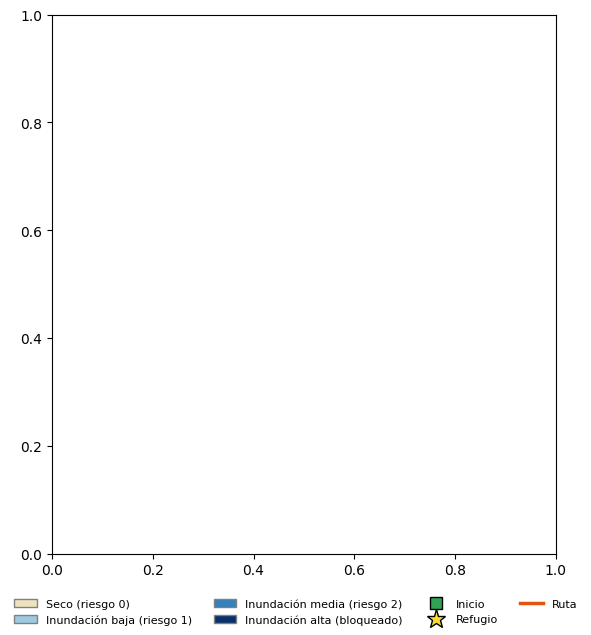

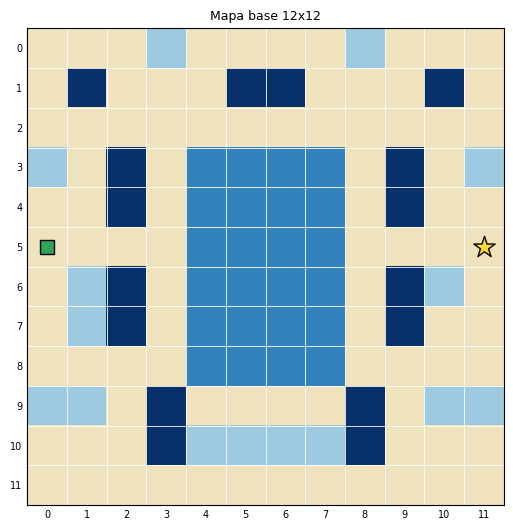

In [ ]:
# Mapa base
fig, ax = plt.subplots(figsize=(6.5, 7))
dibujar_mapa(crear_mapa_base(), INICIO, REFUGIO, titulo="Mapa base 12x12")
agregar_leyenda(fig)
plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.show()

## 6. Escenarios de prueba

Cada escenario muestra las rutas de los 5 algoritmos, una tabla con mediciones reales y comprobaciones automáticas (✅ / ❌).

### Escenario 1: existe una ruta disponible
Mapa base con α = 1. Se espera que todos los algoritmos encuentren una ruta válida, que BFS encuentre la de menos pasos y que Dijkstra y A* encuentren la de menor costo.

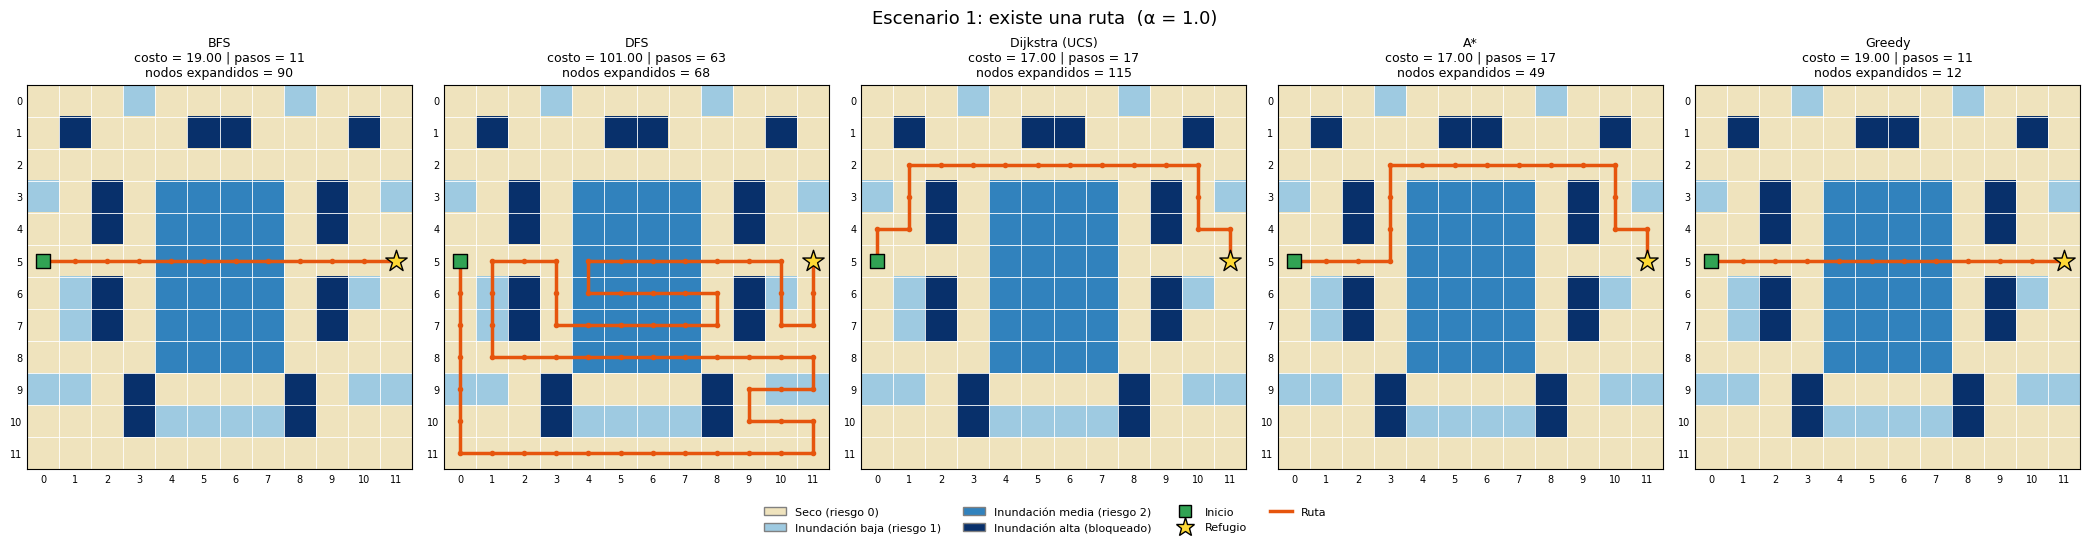

,encontrada,pasos,costo,riesgo_acumulado,nodos_expandidos,tiempo_ms,valida
algoritmo,,,,,,,
BFS,True,11,19.0,8,90,0.6051,True
DFS,True,63,101.0,38,68,0.4629,True
Dijkstra (UCS),True,17,17.0,0,115,1.1162,True
A*,True,17,17.0,0,49,0.5532,True
Greedy,True,11,19.0,8,12,0.0999,True


✅ PASA   Dijkstra encuentra una ruta
✅ PASA   Todas las rutas encontradas son válidas
✅ PASA   A* obtiene el mismo costo que Dijkstra
✅ PASA   Ningún algoritmo obtiene menor costo que Dijkstra
✅ PASA   BFS obtiene la ruta con menos pasos
✅ PASA   A* expande igual o menos nodos que Dijkstra


True

In [ ]:
mapa1 = crear_mapa_base()
res1, tabla1 = comparar(mapa1, INICIO, REFUGIO, alpha=1.0, titulo="Escenario 1: existe una ruta")

E = "1. Ruta disponible"
d1 = res1["Dijkstra (UCS)"]
encontradas1 = [r for r in res1.values() if r["encontrada"]]
prueba(E, "Dijkstra encuentra una ruta", d1["encontrada"])
prueba(E, "Todas las rutas encontradas son válidas", all(r["valida"] for r in encontradas1))
prueba(E, "A* obtiene el mismo costo que Dijkstra", np.isclose(res1["A*"]["costo"], d1["costo"]))
prueba(E, "Ningún algoritmo obtiene menor costo que Dijkstra", all(r["costo"] >= d1["costo"] - 1e-9 for r in encontradas1))
prueba(E, "BFS obtiene la ruta con menos pasos", all(res1["BFS"]["pasos"] <= r["pasos"] for r in encontradas1))
prueba(E, "A* expande igual o menos nodos que Dijkstra", res1["A*"]["nodos_expandidos"] <= d1["nodos_expandidos"])

### Escenario 2: se bloquea una zona que formaba parte de la ruta
Se toma la ruta que obtuvo Dijkstra en el escenario 1 y se bloquea una de sus celdas intermedias. El sistema debe encontrar otra ruta que no pase por ahí. Además, bloquear una celda nunca puede abaratar la mejor ruta.

Se bloquea la celda (2, 6), que era parte de la ruta de Dijkstra.



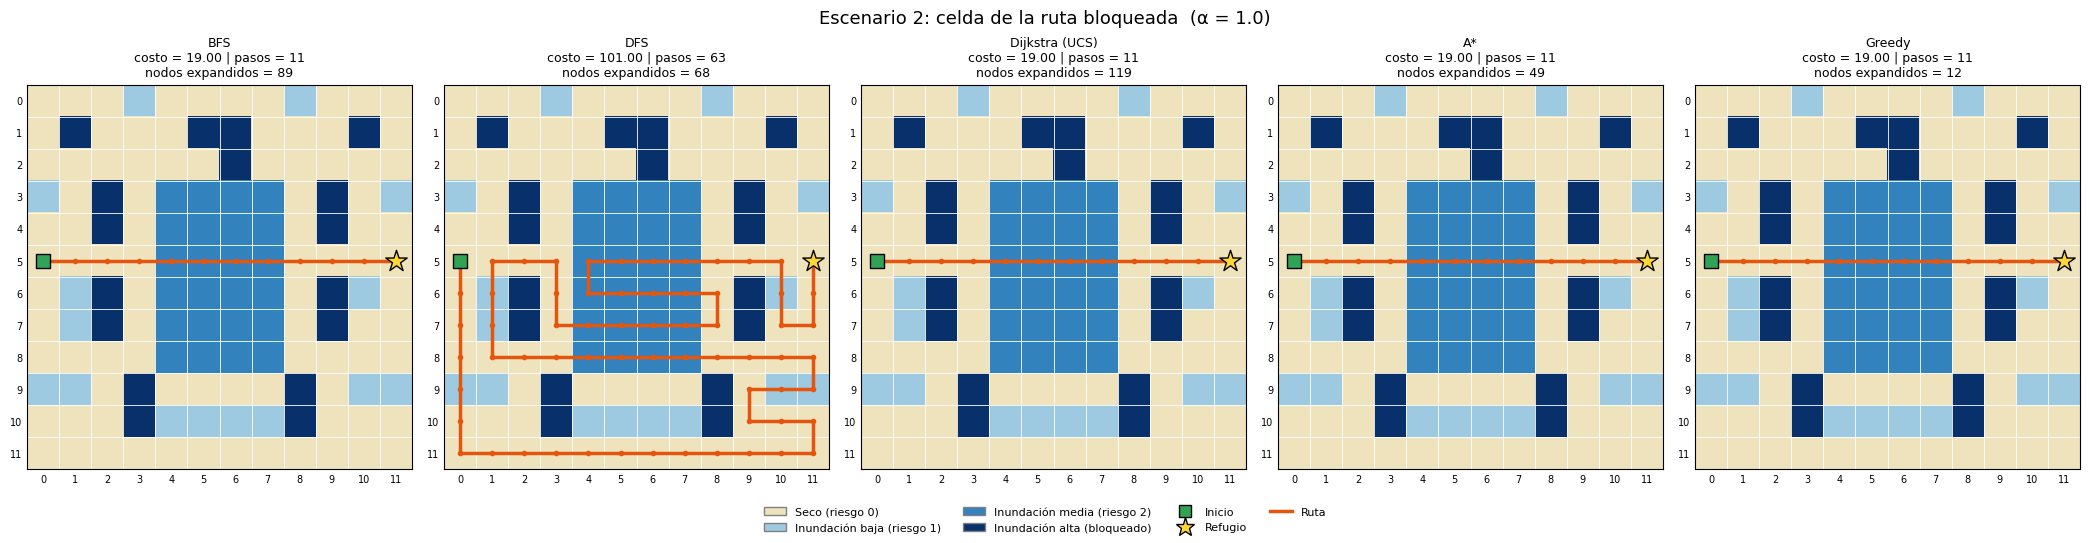

,encontrada,pasos,costo,riesgo_acumulado,nodos_expandidos,tiempo_ms,valida
algoritmo,,,,,,,
BFS,True,11,19.0,8,89,0.4910,True
DFS,True,63,101.0,38,68,0.4084,True
Dijkstra (UCS),True,11,19.0,8,119,1.0642,True
A*,True,11,19.0,8,49,0.5265,True
Greedy,True,11,19.0,8,12,0.1005,True


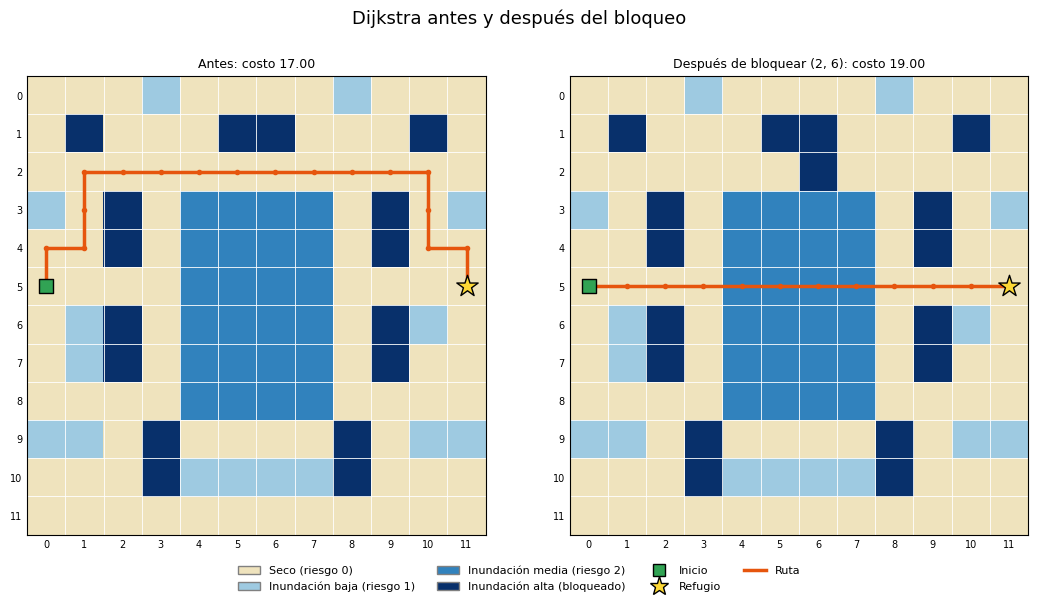

✅ PASA   Sigue existiendo una ruta
✅ PASA   Ninguna ruta pasa por la celda bloqueada (2, 6)
✅ PASA   Todas las rutas son válidas
✅ PASA   El costo óptimo no disminuye al bloquear una celda


True

In [ ]:
mapa2 = crear_mapa_base()
ruta_previa = res1["Dijkstra (UCS)"]["ruta"]
costo_previo = res1["Dijkstra (UCS)"]["costo"]
celda_bloqueada = ruta_previa[len(ruta_previa) // 2]
mapa2[celda_bloqueada] = BLOQUEADO
print(f"Se bloquea la celda {celda_bloqueada}, que era parte de la ruta de Dijkstra.\n")

res2, tabla2 = comparar(mapa2, INICIO, REFUGIO, alpha=1.0, titulo="Escenario 2: celda de la ruta bloqueada")
d2 = res2["Dijkstra (UCS)"]
dibujar_antes_despues(mapa1, ruta_previa, f"Antes: costo {costo_previo:.2f}",
                      mapa2, d2["ruta"], f"Después de bloquear {celda_bloqueada}: costo {d2['costo']:.2f}",
                      titulo="Dijkstra antes y después del bloqueo")

E = "2. Zona de la ruta bloqueada"
encontradas2 = [r for r in res2.values() if r["encontrada"]]
prueba(E, "Sigue existiendo una ruta", d2["encontrada"])
prueba(E, f"Ninguna ruta pasa por la celda bloqueada {celda_bloqueada}", all(celda_bloqueada not in r["ruta"] for r in encontradas2))
prueba(E, "Todas las rutas son válidas", all(r["valida"] for r in encontradas2))
prueba(E, "El costo óptimo no disminuye al bloquear una celda", d2["costo"] >= costo_previo - 1e-9)

### Escenario 3: el refugio deja de ser accesible
Se bloquean todas las celdas vecinas transitables del refugio. Ningún algoritmo debe inventar una ruta, el programa no debe fallar ni quedarse ciclado. También se prueba la variante en la que el propio refugio queda inundado.

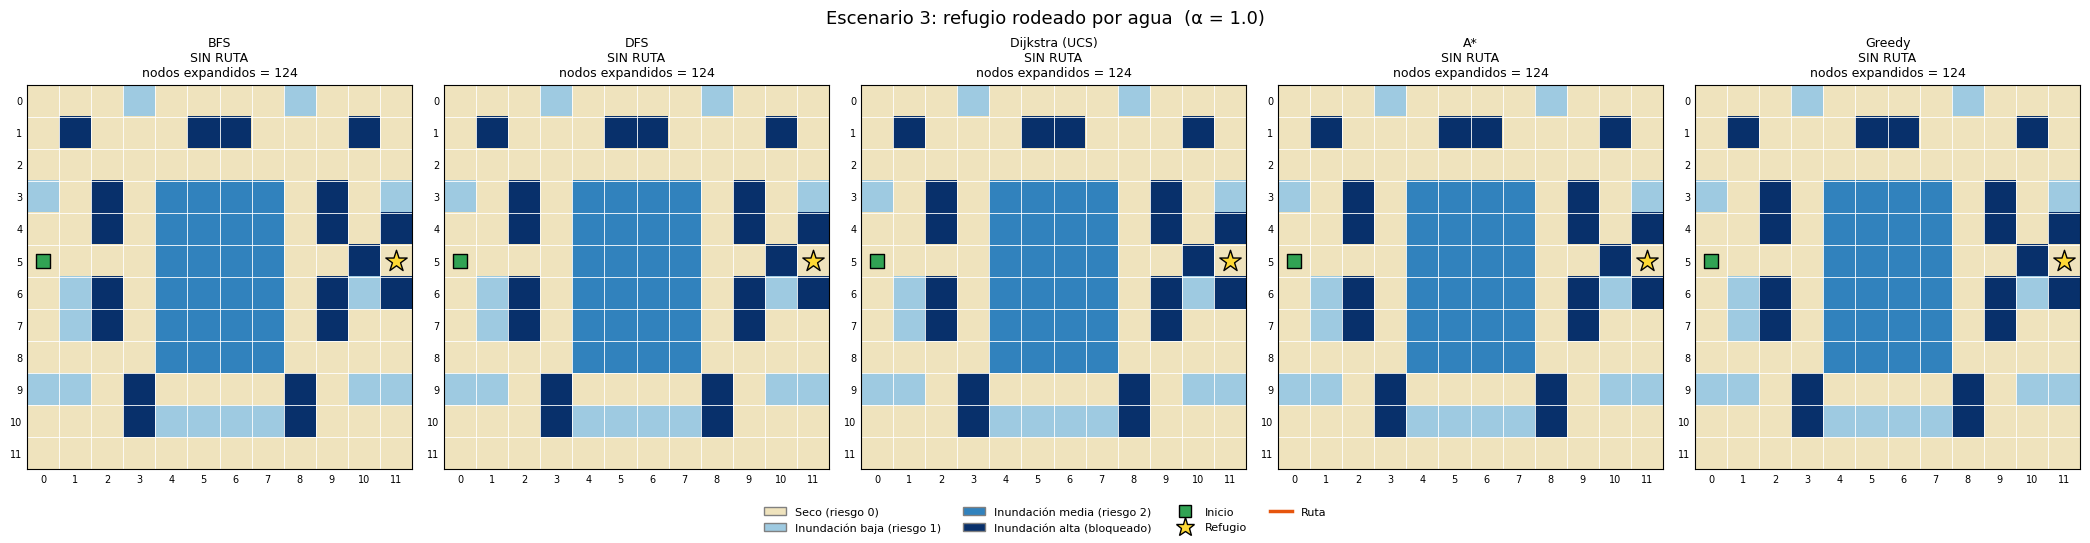

,encontrada,pasos,costo,riesgo_acumulado,nodos_expandidos,tiempo_ms,valida
algoritmo,,,,,,,
BFS,False,None,None,None,124,0.4931,None
DFS,False,None,None,None,124,0.4330,None
Dijkstra (UCS),False,None,None,None,124,0.6078,None
A*,False,None,None,None,124,0.7685,None
Greedy,False,None,None,None,124,0.4957,None


⚠️  El refugio es inaccesible desde el inicio: ningún algoritmo encontró ruta.

Variante: el refugio mismo está bloqueado


,encontrada,pasos,costo,riesgo_acumulado,nodos_expandidos,tiempo_ms,valida
algoritmo,,,,,,,
BFS,False,None,None,None,0,0.0025,None
DFS,False,None,None,None,0,0.0024,None
Dijkstra (UCS),False,None,None,None,0,0.0024,None
A*,False,None,None,None,0,0.0023,None
Greedy,False,None,None,None,0,0.0022,None


✅ PASA   Ningún algoritmo reporta ruta cuando el refugio está rodeado
✅ PASA   Los algoritmos terminan tras explorar la zona alcanzable
✅ PASA   Si el refugio está bloqueado, no se reporta ruta
✅ PASA   Si el refugio está bloqueado, no se gasta búsqueda (0 nodos)


True

In [ ]:
mapa3 = crear_mapa_base()
for celda in [(4, 11), (6, 11), (5, 10)]:
    mapa3[celda] = BLOQUEADO
res3, tabla3 = comparar(mapa3, INICIO, REFUGIO, alpha=1.0, titulo="Escenario 3: refugio rodeado por agua")

mapa3b = crear_mapa_base()
mapa3b[REFUGIO] = BLOQUEADO
res3b, tabla3b = comparar(mapa3b, INICIO, REFUGIO, alpha=1.0, mostrar=False)
print("\nVariante: el refugio mismo está bloqueado")
display(tabla3b)

E = "3. Refugio inaccesible"
prueba(E, "Ningún algoritmo reporta ruta cuando el refugio está rodeado", not any(r["encontrada"] for r in res3.values()))
prueba(E, "Los algoritmos terminan tras explorar la zona alcanzable", all(r["nodos_expandidos"] > 0 for r in res3.values()))
prueba(E, "Si el refugio está bloqueado, no se reporta ruta", not any(r["encontrada"] for r in res3b.values()))
prueba(E, "Si el refugio está bloqueado, no se gasta búsqueda (0 nodos)", all(r["nodos_expandidos"] == 0 for r in res3b.values()))

### Escenario 4: se modifica el riesgo de una región y se vuelve a buscar
El agua baja en la zona central: pasa de inundación media (2) a baja (1). Con el mismo α, cruzar el centro se vuelve más barato y la decisión del algoritmo debe cambiar.

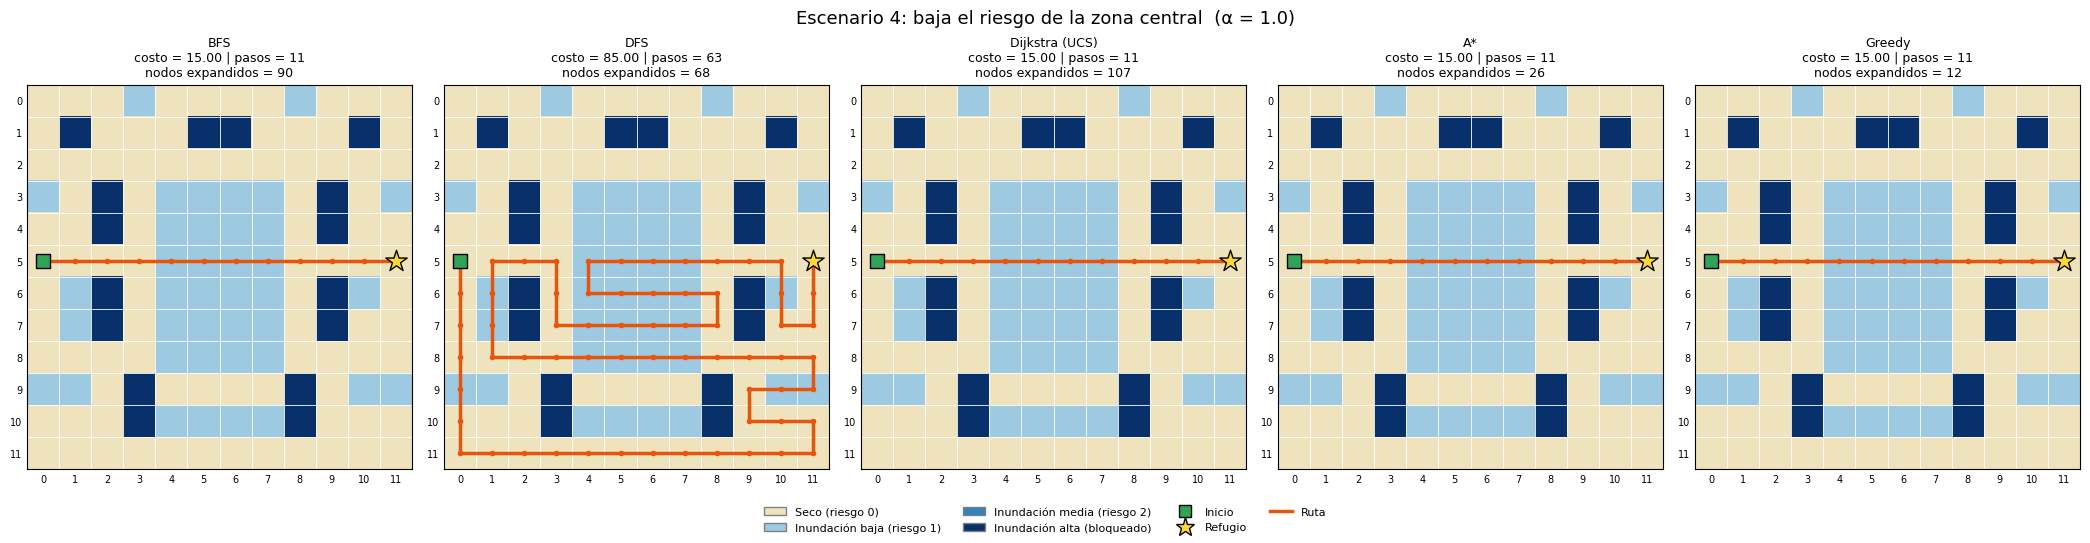

,encontrada,pasos,costo,riesgo_acumulado,nodos_expandidos,tiempo_ms,valida
algoritmo,,,,,,,
BFS,True,11,15.0,4,90,0.2753,True
DFS,True,63,85.0,22,68,0.2188,True
Dijkstra (UCS),True,11,15.0,4,107,0.5116,True
A*,True,11,15.0,4,26,0.1515,True
Greedy,True,11,15.0,4,12,0.0524,True


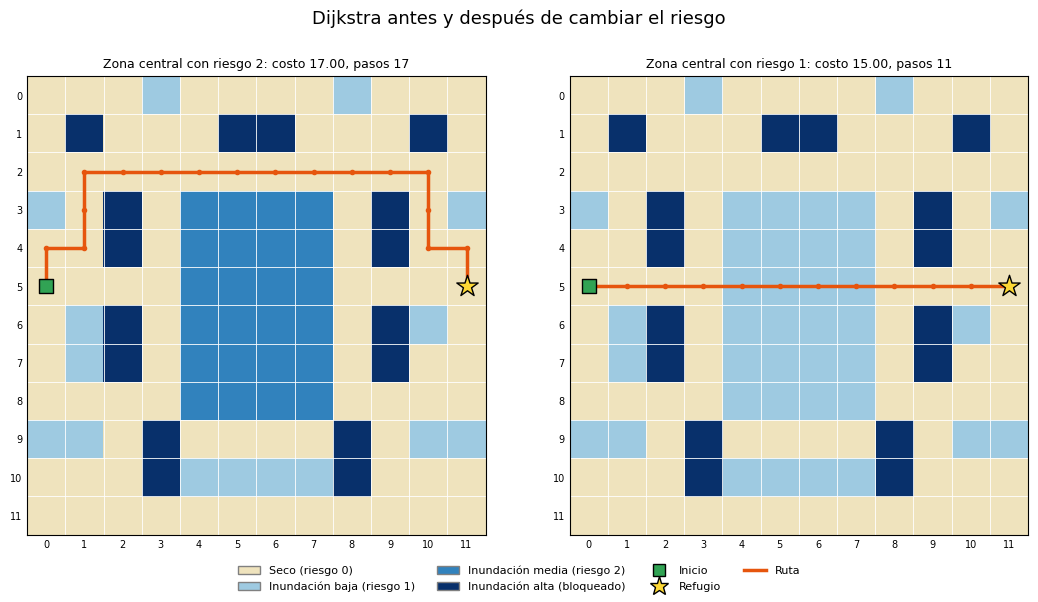

✅ PASA   La ruta elegida cambia al modificar el riesgo
✅ PASA   Con menos riesgo, el costo óptimo es menor o igual
✅ PASA   La ruta anterior, evaluada en el mapa nuevo, no es más barata que la nueva
✅ PASA   Las rutas nuevas son válidas


True

In [ ]:
mapa4 = crear_mapa_base()
antes4 = ejecutar("Dijkstra (UCS)", mapa4, INICIO, REFUGIO, alpha=1.0)

mapa4[3:9, 4:8] = BAJO   # zona central: riesgo 2 -> 1
res4, tabla4 = comparar(mapa4, INICIO, REFUGIO, alpha=1.0, titulo="Escenario 4: baja el riesgo de la zona central")
despues4 = res4["Dijkstra (UCS)"]

dibujar_antes_despues(crear_mapa_base(), antes4["ruta"], f"Zona central con riesgo 2: costo {antes4['costo']:.2f}, pasos {antes4['pasos']}",
                      mapa4, despues4["ruta"], f"Zona central con riesgo 1: costo {despues4['costo']:.2f}, pasos {despues4['pasos']}",
                      titulo="Dijkstra antes y después de cambiar el riesgo")

E = "4. Cambio de riesgo"
prueba(E, "La ruta elegida cambia al modificar el riesgo", antes4["ruta"] != despues4["ruta"])
prueba(E, "Con menos riesgo, el costo óptimo es menor o igual", despues4["costo"] <= antes4["costo"] + 1e-9)
prueba(E, "La ruta anterior, evaluada en el mapa nuevo, no es más barata que la nueva",
       costo_ruta(mapa4, antes4["ruta"], 1.0) >= despues4["costo"] - 1e-9)
prueba(E, "Las rutas nuevas son válidas", all(r["valida"] for r in res4.values() if r["encontrada"]))

### Escenario 5: el camino más corto deja de ser la alternativa más conveniente

Aquí se responde con la implementación la pregunta: **si dos rutas llegan al mismo refugio, pero una es más corta y la otra atraviesa menos riesgo, ¿cuál elige el sistema?**

Se ejecutan BFS (que siempre da la ruta más corta) y Dijkstra (ruta de menor costo) con distintos valores de α sobre el mismo mapa. Cuando α es pequeño ambas coinciden; a partir de cierto valor, Dijkstra prefiere caminar más para evitar el agua.

,alpha,BFS_pasos,BFS_riesgo,BFS_costo,Dijkstra_pasos,Dijkstra_riesgo,Dijkstra_costo
0,0.00,11,8,11.0,11,8,11.0
1,0.25,11,8,13.0,11,8,13.0
2,0.50,11,8,15.0,11,8,15.0
3,0.75,11,8,17.0,11,8,17.0
4,1.00,11,8,19.0,17,0,17.0
5,1.50,11,8,23.0,17,0,17.0
6,2.00,11,8,27.0,17,0,17.0
7,3.00,11,8,35.0,17,0,17.0
8,5.00,11,8,51.0,17,0,17.0


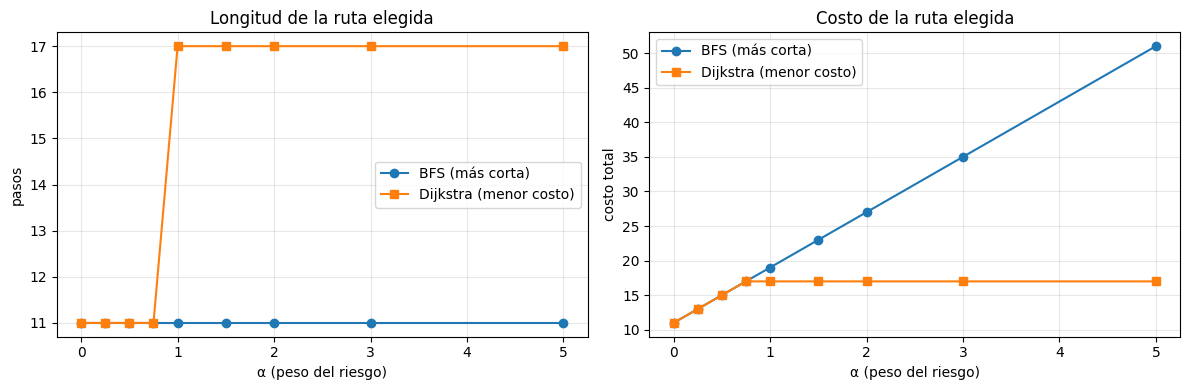

,pasos,riesgo_acumulado,costo con α=3
ruta,,,
Más corta (BFS),11,8,35.0
Elegida por el sistema (Dijkstra),17,0,17.0


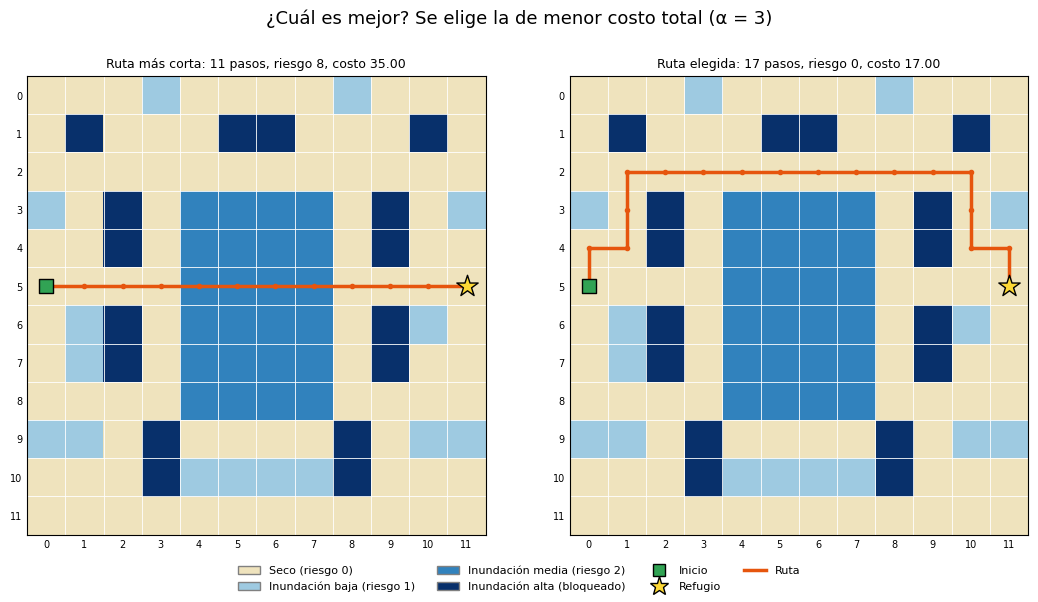

✅ PASA   Con α = 0 Dijkstra elige una ruta tan corta como la de BFS
✅ PASA   Con α = 3 la ruta elegida es más larga que la más corta
✅ PASA   Con α = 3 la ruta elegida tiene menor riesgo y menor costo total
✅ PASA   Para todo α, el costo de Dijkstra es <= al de la ruta más corta


True

In [ ]:
mapa5 = crear_mapa_base()
alphas = [0, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 5]
filas = []
for a in alphas:
    b = ejecutar("BFS", mapa5, INICIO, REFUGIO, a, repeticiones=1)
    d = ejecutar("Dijkstra (UCS)", mapa5, INICIO, REFUGIO, a, repeticiones=1)
    filas.append({"alpha": a,
                  "BFS_pasos": b["pasos"], "BFS_riesgo": b["riesgo_acumulado"], "BFS_costo": b["costo"],
                  "Dijkstra_pasos": d["pasos"], "Dijkstra_riesgo": d["riesgo_acumulado"], "Dijkstra_costo": d["costo"]})
barrido = pd.DataFrame(filas)
display(barrido)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(barrido.alpha, barrido.BFS_pasos, "o-", label="BFS (más corta)")
ejes[0].plot(barrido.alpha, barrido.Dijkstra_pasos, "s-", label="Dijkstra (menor costo)")
ejes[0].set(xlabel="α (peso del riesgo)", ylabel="pasos", title="Longitud de la ruta elegida")
ejes[1].plot(barrido.alpha, barrido.BFS_costo, "o-", label="BFS (más corta)")
ejes[1].plot(barrido.alpha, barrido.Dijkstra_costo, "s-", label="Dijkstra (menor costo)")
ejes[1].set(xlabel="α (peso del riesgo)", ylabel="costo total", title="Costo de la ruta elegida")
for ax in ejes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Comparación directa de las dos rutas con α = 3
ALPHA = 3
corta = ejecutar("BFS", mapa5, INICIO, REFUGIO, ALPHA)
segura = ejecutar("Dijkstra (UCS)", mapa5, INICIO, REFUGIO, ALPHA)
comparacion = pd.DataFrame([
    {"ruta": "Más corta (BFS)", "pasos": corta["pasos"], "riesgo_acumulado": corta["riesgo_acumulado"], f"costo con α={ALPHA}": corta["costo"]},
    {"ruta": "Elegida por el sistema (Dijkstra)", "pasos": segura["pasos"], "riesgo_acumulado": segura["riesgo_acumulado"], f"costo con α={ALPHA}": segura["costo"]},
]).set_index("ruta")
display(comparacion)
dibujar_antes_despues(mapa5, corta["ruta"], f"Ruta más corta: {corta['pasos']} pasos, riesgo {corta['riesgo_acumulado']}, costo {corta['costo']:.2f}",
                      mapa5, segura["ruta"], f"Ruta elegida: {segura['pasos']} pasos, riesgo {segura['riesgo_acumulado']}, costo {segura['costo']:.2f}",
                      titulo=f"¿Cuál es mejor? Se elige la de menor costo total (α = {ALPHA})")

E = "5. El más corto deja de ser el mejor"
fila0 = barrido.iloc[0]
prueba(E, "Con α = 0 Dijkstra elige una ruta tan corta como la de BFS", fila0.Dijkstra_pasos == fila0.BFS_pasos)
prueba(E, f"Con α = {ALPHA} la ruta elegida es más larga que la más corta", segura["pasos"] > corta["pasos"])
prueba(E, f"Con α = {ALPHA} la ruta elegida tiene menor riesgo y menor costo total",
       segura["riesgo_acumulado"] < corta["riesgo_acumulado"] and segura["costo"] < corta["costo"])
prueba(E, "Para todo α, el costo de Dijkstra es <= al de la ruta más corta",
       all(barrido.Dijkstra_costo <= barrido.BFS_costo + 1e-9))

## 7. Prueba adicional: detectar errores en nuestra propia implementación

Esta prueba no se limita a volver a ejecutar el programa: busca **fallos reales**.

**7.1 Consistencia en cientos de mapas aleatorios.** Dijkstra es el algoritmo de referencia porque garantiza el costo mínimo. En 300 mapas aleatorios (de 10x10 a 20x20, con α aleatorio) se comprueba que:
- A* obtiene exactamente el mismo costo que Dijkstra (si no, la heurística o la cola de prioridad tienen un error),
- BFS, Dijkstra y A* coinciden en si el refugio es alcanzable o no,
- todas las rutas pasan el validador y el costo interno coincide con el recalculado.

**Control:** para demostrar que la prueba realmente es capaz de detectar errores, se repite con una versión de A* intencionalmente defectuosa (heurística multiplicada por 3, que ya no es admisible). La prueba **debe** encontrar discrepancias en ese caso.

**7.2 El validador también se prueba.** Si el validador tuviera un error, aceptaría rutas incorrectas sin que nos diéramos cuenta. Se le dan rutas dañadas a propósito y se comprueba que las rechaza todas.

In [ ]:
def prueba_consistencia(n_mapas=300, peso_heuristica=1.0, semilla_base=1000):
    rng = random.Random(semilla_base)
    discrepancias, alcanzables = [], 0
    for i in range(n_mapas):
        n = rng.randint(10, 20)
        alpha = round(rng.uniform(0, 3), 2)
        mapa = generar_mapa(n, semilla_base + i, p_bloqueo=0.25)
        ini, ref = (0, 0), (n - 1, n - 1)
        r_d, _, c_d = dijkstra(mapa, ini, ref, alpha)
        r_a, _, c_a = a_estrella(mapa, ini, ref, alpha, peso_heuristica=peso_heuristica)
        r_b, _, _ = bfs(mapa, ini, ref, alpha)
        problemas = []
        if not ((r_d is None) == (r_a is None) == (r_b is None)):
            problemas.append("no coinciden en si el refugio es alcanzable")
        elif r_d is not None:
            alcanzables += 1
            if not np.isclose(costo_ruta(mapa, r_d, alpha), costo_ruta(mapa, r_a, alpha)):
                problemas.append("A* y Dijkstra dan costos distintos")
            for nombre, r, c in [("Dijkstra", r_d, c_d), ("A*", r_a, c_a), ("BFS", r_b, None)]:
                ok, err = validar_ruta(mapa, r, ini, ref, alpha, c)
                if not ok:
                    problemas.append(f"ruta de {nombre} inválida: {err}")
        if problemas:
            discrepancias.append({
                "mapa": i, "tamaño": n, "alpha": alpha, "problemas": "; ".join(problemas),
                "costo_dijkstra": round(costo_ruta(mapa, r_d, alpha), 2) if r_d else None,
                "costo_a*": round(costo_ruta(mapa, r_a, alpha), 2) if r_a else None,
            })
    return discrepancias, alcanzables


E = "7. Prueba adicional"
disc_real, alc = prueba_consistencia(peso_heuristica=1.0)
print(f"A* correcto: {alc} de 300 mapas con refugio alcanzable, {len(disc_real)} discrepancias.")
prueba(E, "A* coincide con Dijkstra y todas las rutas son válidas en 300 mapas aleatorios", len(disc_real) == 0)

disc_control, _ = prueba_consistencia(peso_heuristica=3.0)
print(f"\nControl con A* defectuoso (heurística x3): {len(disc_control)} discrepancias detectadas.")
if disc_control:
    display(pd.DataFrame(disc_control).head(10))
prueba(E, "Control: la prueba detecta una heurística no admisible", len(disc_control) > 0)

A* correcto: 215 de 300 mapas con refugio alcanzable, 0 discrepancias.
✅ PASA   A* coincide con Dijkstra y todas las rutas son válidas en 300 mapas aleatorios

Control con A* defectuoso (heurística x3): 155 discrepancias detectadas.


,mapa,tamaño,alpha,problemas,costo_dijkstra,costo_a*
0,0,16,2.01,A* y Dijkstra dan costos distintos,58.14,60.15
1,2,11,1.40,A* y Dijkstra dan costos distintos,29.80,32.60
2,5,20,0.72,A* y Dijkstra dan costos distintos,48.08,50.24
3,6,20,1.47,A* y Dijkstra dan costos distintos,63.52,70.87
4,9,17,0.55,A* y Dijkstra dan costos distintos,46.10,49.20
5,11,17,0.43,A* y Dijkstra dan costos distintos,36.30,36.73
6,12,16,2.07,A* y Dijkstra dan costos distintos,77.33,79.47
7,13,13,0.07,A* y Dijkstra dan costos distintos,24.63,24.91
8,20,20,2.56,A* y Dijkstra dan costos distintos,75.84,81.52
9,26,11,0.88,A* y Dijkstra dan costos distintos,27.04,27.92


✅ PASA   Control: la prueba detecta una heurística no admisible


True

In [ ]:
mapa_v = crear_mapa_base()
ruta_ok = res1["Dijkstra (UCS)"]["ruta"]
costo_ok = costo_ruta(mapa_v, ruta_ok, 1.0)

mapa_con_bloqueo = crear_mapa_base()
mapa_con_bloqueo[ruta_ok[4]] = BLOQUEADO

casos_invalidos = [
    ("Salto: se elimina una celda intermedia", mapa_v, ruta_ok[:3] + ruta_ok[4:], None),
    ("Pasa por una celda bloqueada", mapa_con_bloqueo, ruta_ok, None),
    ("No termina en el refugio", mapa_v, ruta_ok[:-1], None),
    ("No empieza en el inicio", mapa_v, ruta_ok[1:], None),
    ("Sale del mapa", mapa_v, ruta_ok + [(5, 12)], None),
    ("Repite celdas (ciclo)", mapa_v, ruta_ok[:3] + ruta_ok[1:], None),
    ("Costo reportado incorrecto", mapa_v, ruta_ok, costo_ok + 1),
]

filas = []
for descripcion, mapa_caso, ruta_caso, costo_caso in casos_invalidos:
    ok, errores = validar_ruta(mapa_caso, ruta_caso, INICIO, REFUGIO, 1.0, costo_caso)
    filas.append({"caso": descripcion, "rechazada": not ok, "motivo detectado": errores[0] if errores else "-"})
tabla_validador = pd.DataFrame(filas)
display(tabla_validador)

prueba(E, "El validador acepta una ruta correcta", validar_ruta(mapa_v, ruta_ok, INICIO, REFUGIO, 1.0, costo_ok)[0])
prueba(E, "El validador rechaza las 7 rutas dañadas a propósito", tabla_validador.rechazada.all())

,caso,rechazada,motivo detectado
0,Salto: se elimina una celda intermedia,True,"Movimiento inválido de (4, 1) a (2, 1)"
1,Pasa por una celda bloqueada,True,"La celda (2, 1) está bloqueada"
2,No termina en el refugio,True,"No termina en el refugio (5, 11), termina en (..."
3,No empieza en el inicio,True,"No empieza en el inicio (5, 0), empieza en (4, 0)"
4,Sale del mapa,True,"No termina en el refugio (5, 11), termina en (..."
5,Repite celdas (ciclo),True,La ruta repite celdas
6,Costo reportado incorrecto,True,Costo reportado 18.0 distinto del real 17.0


✅ PASA   El validador acepta una ruta correcta
✅ PASA   El validador rechaza las 7 rutas dañadas a propósito


True

## 8. Comparación en mapas más grandes

Para que la comparación no dependa de un solo mapa, se ejecutan los 5 algoritmos en 10 mapas aleatorios de cada tamaño (15x15, 25x25 y 40x40) con α = 1. Solo se consideran mapas donde el refugio es alcanzable.

- **costo_relativo**: costo de la ruta / costo óptimo (Dijkstra). 1.0 significa ruta óptima.
- **% rutas óptimas**: porcentaje de mapas en que el algoritmo obtuvo el costo mínimo.

mapas  nodos_expandidos_prom  tiempo_ms_prom  costo_relativo_prom  pct_rutas_optimas  todas_validas
tamaño algoritmo                                                                                                          
15     A*                  9                126.667           0.782                1.000              100.0           True
       BFS                 9                173.889           0.606                1.237                0.0           True
       DFS                 9                 59.667           0.232                2.343                0.0           True
       Dijkstra (UCS)      9                173.222           0.986                1.000              100.0           True
       Greedy              9                 41.444           0.188                1.261                0.0           True
25     A*                  7                327.714           1.947                1.000              100.0           True
       BFS                 7                500.857           1.605                1.295                0.0           True
       DFS                 7                180.571           0.653                2.901                0.0           True
       Dijkstra (UCS)      7                499.000           2.555                1.000              100.0           True
       Greedy              7                 62.429           0.275                1.473                0.0           True
40     A*                  8               1047.500           6.252                1.000              100.0           True
       BFS                 8               1270.500           4.199                1.279                0.0           True
       DFS                 8                410.000           1.515                4.240                0.0           True
       Dijkstra (UCS)      8               1270.250           7.039                1.000              100.0           True
       Greedy              8                110.000           0.584                1.512                0.0           True

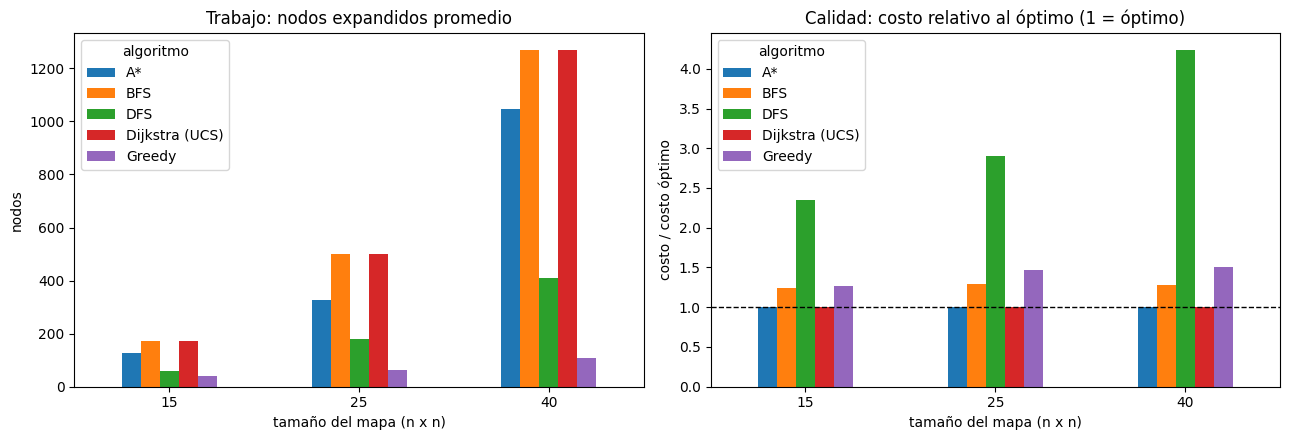

✅ PASA   Todas las rutas en mapas grandes son válidas
✅ PASA   A* es óptimo en todos los mapas grandes


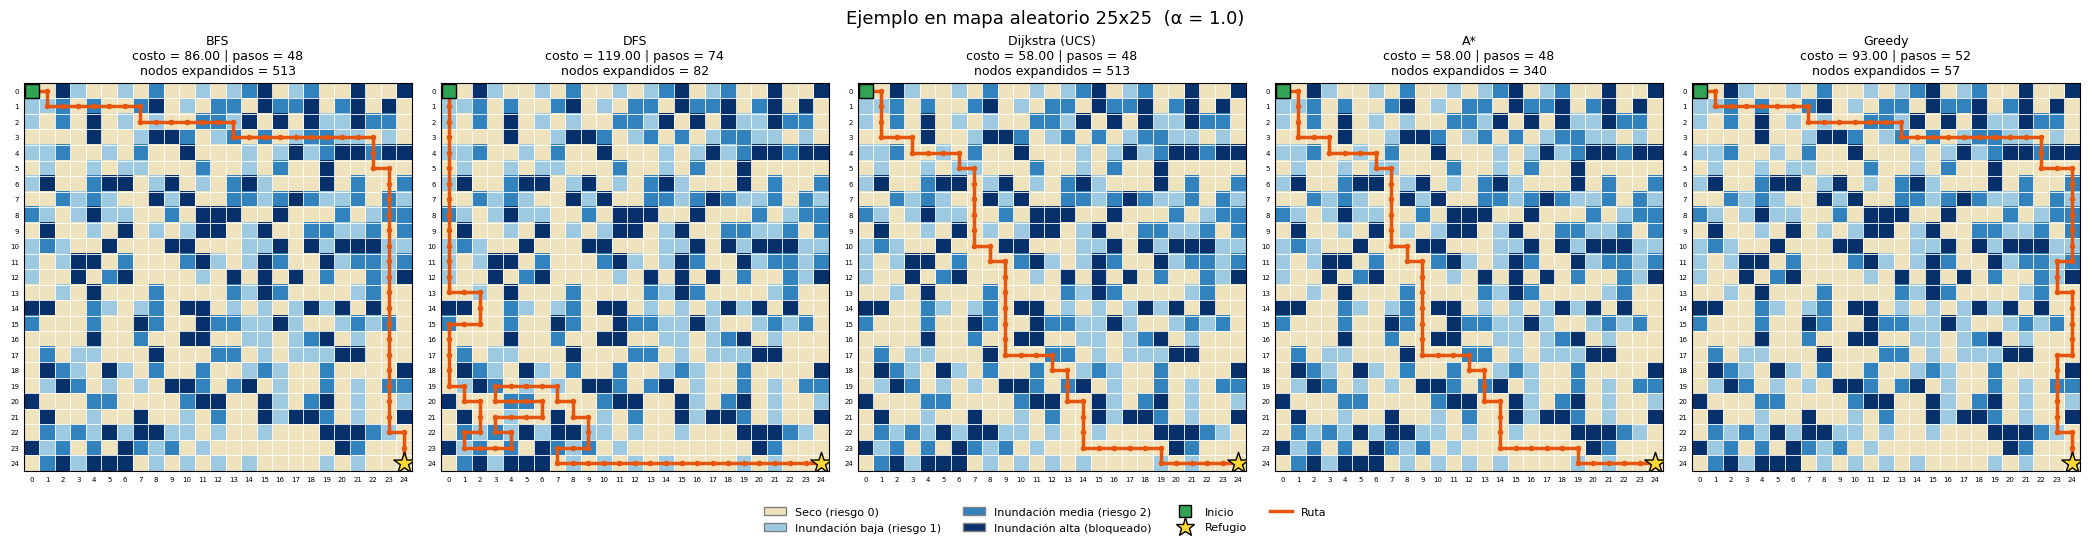

,encontrada,pasos,costo,riesgo_acumulado,nodos_expandidos,tiempo_ms,valida
algoritmo,,,,,,,
BFS,True,48,86.0,38,513,1.7421,True
DFS,True,74,119.0,45,82,0.2734,True
Dijkstra (UCS),True,48,58.0,10,513,2.6717,True
A*,True,48,58.0,10,340,2.2371,True
Greedy,True,52,93.0,41,57,0.2877,True


In [ ]:
filas = []
for n in [15, 25, 40]:
    for semilla in range(10):
        mapa = generar_mapa(n, semilla, p_bloqueo=0.2)
        ini, ref = (0, 0), (n - 1, n - 1)
        optimo = ejecutar("Dijkstra (UCS)", mapa, ini, ref, 1.0, repeticiones=5)
        if not optimo["encontrada"]:
            continue
        for nombre in ALGORITMOS:
            r = optimo if nombre == "Dijkstra (UCS)" else ejecutar(nombre, mapa, ini, ref, 1.0, repeticiones=5)
            filas.append({"tamaño": n, "semilla": semilla, "algoritmo": nombre,
                          "costo_relativo": r["costo"] / optimo["costo"],
                          "optima": bool(np.isclose(r["costo"], optimo["costo"])),
                          "nodos_expandidos": r["nodos_expandidos"],
                          "tiempo_ms": r["tiempo_ms"], "valida": r["valida"]})
datos = pd.DataFrame(filas)

resumen = (datos.groupby(["tamaño", "algoritmo"])
           .agg(mapas=("semilla", "nunique"),
                nodos_expandidos_prom=("nodos_expandidos", "mean"),
                tiempo_ms_prom=("tiempo_ms", "mean"),
                costo_relativo_prom=("costo_relativo", "mean"),
                pct_rutas_optimas=("optima", "mean"),
                todas_validas=("valida", "all"))
           .round(3))
resumen["pct_rutas_optimas"] = (resumen["pct_rutas_optimas"] * 100).round(1)
display(resumen)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
resumen["nodos_expandidos_prom"].unstack("algoritmo").plot.bar(ax=ejes[0], rot=0)
ejes[0].set(title="Trabajo: nodos expandidos promedio", xlabel="tamaño del mapa (n x n)", ylabel="nodos")
resumen["costo_relativo_prom"].unstack("algoritmo").plot.bar(ax=ejes[1], rot=0)
ejes[1].axhline(1, color="black", linestyle="--", linewidth=1)
ejes[1].set(title="Calidad: costo relativo al óptimo (1 = óptimo)", xlabel="tamaño del mapa (n x n)", ylabel="costo / costo óptimo")
plt.tight_layout(); plt.show()

prueba("8. Mapas grandes", "Todas las rutas en mapas grandes son válidas", datos.valida.all())
prueba("8. Mapas grandes", "A* es óptimo en todos los mapas grandes", datos[datos.algoritmo == "A*"].optima.all())

# Ejemplo visual en un mapa de 25x25
mapa_g = generar_mapa(25, 3, p_bloqueo=0.2)
_ = comparar(mapa_g, (0, 0), (24, 24), alpha=1.0, titulo="Ejemplo en mapa aleatorio 25x25", repeticiones=5)

## 9. Resumen de pruebas

In [ ]:
resumen_pruebas = pd.DataFrame(REGISTRO_PRUEBAS)
display(resumen_pruebas)
total, pasan = len(resumen_pruebas), (resumen_pruebas.resultado == "PASA").sum()
print(f"\n{pasan} de {total} comprobaciones pasan.")

,escenario,comprobación,resultado
0,1. Ruta disponible,Dijkstra encuentra una ruta,PASA
1,1. Ruta disponible,Todas las rutas encontradas son válidas,PASA
2,1. Ruta disponible,A* obtiene el mismo costo que Dijkstra,PASA
3,1. Ruta disponible,Ningún algoritmo obtiene menor costo que Dijkstra,PASA
4,1. Ruta disponible,BFS obtiene la ruta con menos pasos,PASA
5,1. Ruta disponible,A* expande igual o menos nodos que Dijkstra,PASA
6,2. Zona de la ruta bloqueada,Sigue existiendo una ruta,PASA
7,2. Zona de la ruta bloqueada,"Ninguna ruta pasa por la celda bloqueada (2, 6)",PASA
8,2. Zona de la ruta bloqueada,Todas las rutas son válidas,PASA
9,2. Zona de la ruta bloqueada,El costo óptimo no disminuye al bloquear una c...,PASA



28 de 28 comprobaciones pasan.


## 10. Decisiones de diseño y conclusiones

> Revisen y completen esta sección con sus propias palabras y con los números que obtuvieron en las tablas de arriba.

**Representación.** Se usó una matriz porque permite ver directamente el terreno, modificar zonas con una sola línea (por ejemplo `mapa[3:9, 4:8] = BAJO`) y dibujarlo con `imshow`. Se eligieron 4 direcciones de movimiento para evitar cruzar en diagonal entre dos celdas bloqueadas.

**Riesgo.** El riesgo se convierte en costo con `1 + α·riesgo`. El "1" garantiza que la distancia siempre cuenta y que el costo mínimo de un paso es 1, lo que hace admisible la heurística Manhattan de A*. Las zonas de inundación alta se tratan como bloqueos (restricción dura) y no como un costo muy alto, porque cruzarlas no debe ser posible en ningún caso.

**Encontrar una ruta vs. encontrar una ruta conveniente.** BFS, DFS y Greedy *encuentran una ruta*, pero no consideran el riesgo, así que pueden llevar al agente por el agua. Dijkstra y A* encuentran la *ruta conveniente* (la de menor costo total). Esto se observa en el escenario 1 y en el escenario 5.

**Respuesta a la pregunta principal.** Si dos rutas llegan al refugio y una es más corta pero más riesgosa, el sistema calcula el costo total de cada una y elige la menor. El escenario 5 lo demuestra: con α = 0 se elige la ruta más corta; al aumentar α, a partir de cierto valor se elige el rodeo seco porque su costo total es menor.


**Limitaciones.** El riesgo es estático (no cambia con el tiempo), el movimiento es solo en 4 direcciones y α lo elige el usuario; en un caso real habría que calibrarlo con expertos en protección civil.

## 11. Declaración de uso de IA


- **Herramientas utilizadas:** Claude
- **Cómo se verificó el código:**
  - Se revisó y se entendió cada función antes de usarla.
  - Se comprobaron a mano rutas y costos en el mapa base 12x12.
  - Cada ruta pasa por un validador independiente (sección 4).
  - Se compararon A* y Dijkstra en 300 mapas aleatorios y se comprobó que la prueba detecta una heurística defectuosa (sección 7).
